# Аналіз класифікатора «є корабель / немає»

Етап 5, крок 6. Модель уже навчена (`03_classifier_train.ipynb`, Kaggle), тут лише її передбачення
на val — `data/classifier_v1/val_probs.csv`: для кожного з 19 256 val-знімків правда (`n_ships`)
і ймовірність `p`. Усе рахується локально, без GPU.

1. Криві навчання — чи модель ще вчилась, чи вже перенавчалась.
2. Розподіл p для порожніх знімків і знімків з кораблями.
3. ROC-крива і PR-крива.
4. Пороги: помилки класифікатора і **стеля** для всього пайплайну.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

ROOT = Path.cwd().parent
RESULTS_DIR = ROOT / "data" / "classifier_v1"

EMPTY_COLOR = "#2a78d6"
SHIPS_COLOR = "#eb6834"

history = pd.read_csv(RESULTS_DIR / "history.csv")
val = pd.read_csv(RESULTS_DIR / "val_probs.csv")
val["has_ships"] = val["n_ships"] > 0

print("val-знімків:", len(val))
print(f"з кораблями: {val['has_ships'].sum()} ({val['has_ships'].mean():.1%})")

val-знімків: 19256
з кораблями: 4256 (22.1%)


## 1. Криві навчання

Ліворуч — loss на train і val, праворуч — val ROC-AUC. Шукаємо: чи val loss ще падає (модель вчиться),
чи вже росте, поки train падає (перенавчання).

Val loss нижчий за train loss — не помилка: на train діють аугментації, і train loss усереднений
по всій епосі, поки модель ще покращувалась, а val рахується вже після епохи.

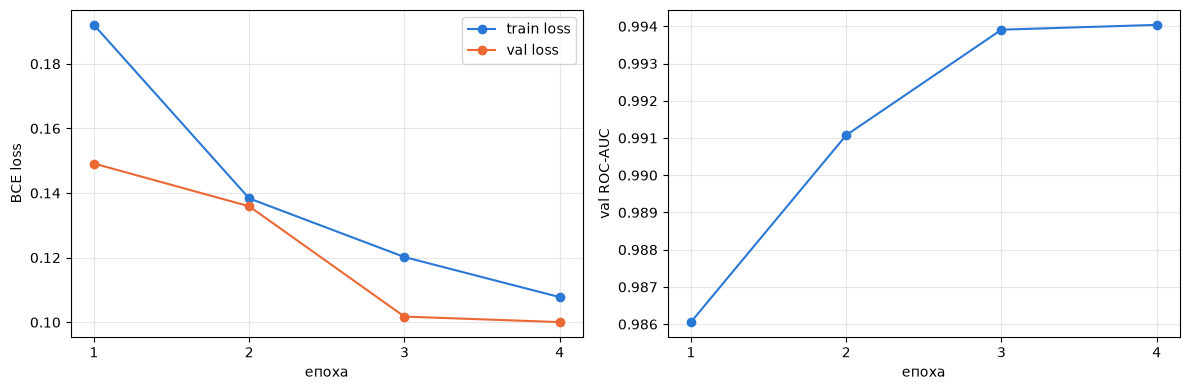

,epoch,train_loss,val_loss,val_auc,minutes
0,1,0.1921,0.1491,0.9861,11.2203
1,2,0.1383,0.1359,0.9911,11.3321
2,3,0.1202,0.1017,0.9939,10.9326
3,4,0.1078,0.1000,0.9940,10.9389


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["train_loss"], marker="o", color=EMPTY_COLOR, label="train loss")
axes[0].plot(history["epoch"], history["val_loss"], marker="o", color=SHIPS_COLOR, label="val loss")
axes[0].set_xlabel("епоха")
axes[0].set_ylabel("BCE loss")
axes[0].set_xticks(history["epoch"])
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history["epoch"], history["val_auc"], marker="o", color=EMPTY_COLOR)
axes[1].set_xlabel("епоха")
axes[1].set_ylabel("val ROC-AUC")
axes[1].set_xticks(history["epoch"])
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

history.round(4)

## 2. Розподіл p для двох класів

Хочемо, щоб порожні знімки тулились до p = 0, а знімки з кораблями — до 1. Там, де гістограми
перекриваються, модель і помиляється.

Вісь y — логарифмічна: порожніх знімків утричі більше, і без логарифма «хвости», де живуть помилки,
не було б видно.

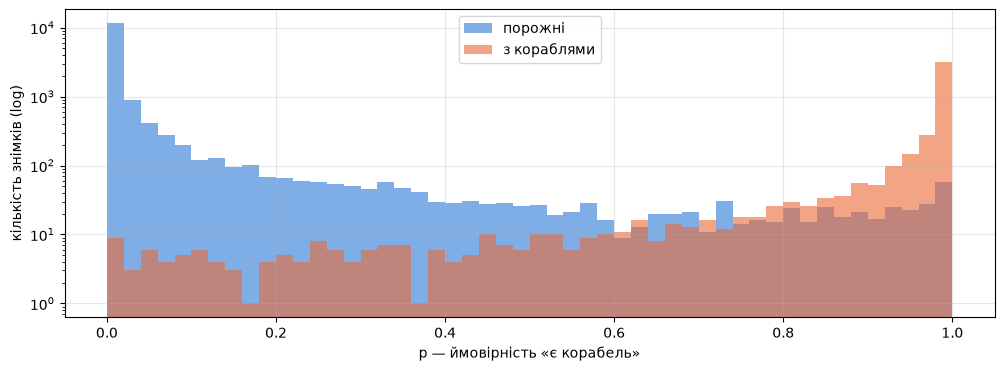

,count,mean,std,min,5%,50%,95%,max
has_ships,,,,,,,,
False,15000.0,0.056,0.158,0.000,0.000,0.005,0.359,1.0
True,4256.0,0.948,0.146,0.005,0.663,0.997,1.000,1.0


In [3]:
bins = np.linspace(0, 1, 51)
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(val.loc[~val["has_ships"], "p"], bins=bins, color=EMPTY_COLOR, alpha=0.6, label="порожні")
ax.hist(val.loc[val["has_ships"], "p"], bins=bins, color=SHIPS_COLOR, alpha=0.6, label="з кораблями")
ax.set_yscale("log")
ax.set_xlabel("p — ймовірність «є корабель»")
ax.set_ylabel("кількість знімків (log)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

val.groupby("has_ships")["p"].describe(percentiles=[0.05, 0.5, 0.95]).round(3)

## 3. ROC-крива і PR-крива

- **ROC:** TPR = TP / (TP + FN) (частка знімків з кораблями, які пройдуть далі) проти
  FPR = FP / (FP + TN) (частка порожніх, хибно названих «є корабель»). Навмання — діагональ, AUC = 0.5.
- **PR:** recall (= TPR) проти precision = TP / (TP + FP). Навмання — горизонталь на рівні частки
  знімків з кораблями (~0.22). Підсумкове число — **AP (Average Precision)**.

Точками позначено пороги 0.1, 0.3, 0.5, 0.7, 0.9 — щоб бачити, де на кривій який поріг.
ROC показано **збільшено** (FPR до 0.2, TPR від 0.85): решта кривої — пряма лінія вгорі,
а діагональ «навмання» в цю ділянку не потрапляє.

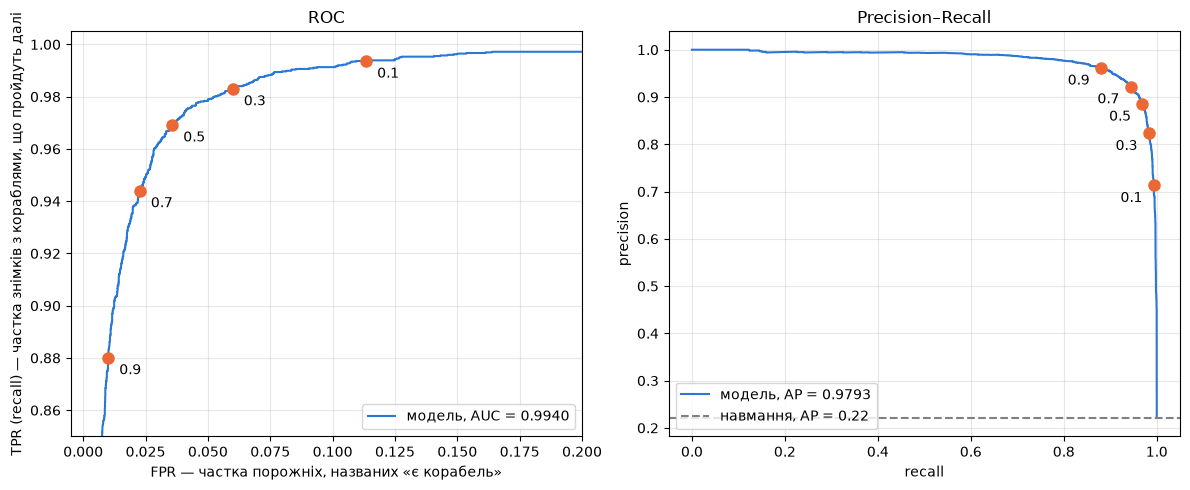

ROC-AUC = 0.9940, AP = 0.9793


In [4]:
y_true = val["has_ships"].values
y_score = val["p"].values
marked_thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
precision, recall, pr_thresholds = precision_recall_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)
ap = average_precision_score(y_true, y_score)


def at_threshold(t):
    predicted = y_score > t
    tp = (predicted & y_true).sum()
    fp = (predicted & ~y_true).sum()
    fn = (~predicted & y_true).sum()
    tn = (~predicted & ~y_true).sum()
    return tp, fp, fn, tn


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, color=EMPTY_COLOR, label=f"модель, AUC = {auc:.4f}")
# Уся цікава частина ROC — у лівому верхньому куті, тож показуємо лише його.
axes[0].set_xlim(-0.005, 0.2)
axes[0].set_ylim(0.85, 1.005)
axes[1].plot(recall, precision, color=EMPTY_COLOR, label=f"модель, AP = {ap:.4f}")
axes[1].axhline(y_true.mean(), color="gray", linestyle="--", label=f"навмання, AP = {y_true.mean():.2f}")

for t in marked_thresholds:
    tp, fp, fn, tn = at_threshold(t)
    axes[0].plot(fp / (fp + tn), tp / (tp + fn), "o", color=SHIPS_COLOR, markersize=8)
    axes[0].annotate(f"{t}", (fp / (fp + tn), tp / (tp + fn)), textcoords="offset points", xytext=(8, -12))
    axes[1].plot(tp / (tp + fn), tp / (tp + fp), "o", color=SHIPS_COLOR, markersize=8)
    axes[1].annotate(f"{t}", (tp / (tp + fn), tp / (tp + fp)), textcoords="offset points", xytext=(-24, -12))

axes[0].set_xlabel("FPR — частка порожніх, названих «є корабель»")
axes[0].set_ylabel("TPR (recall) — частка знімків з кораблями, що пройдуть далі")
axes[0].set_title("ROC")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision–Recall")
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[1] else "lower right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC = {auc:.4f}, AP = {ap:.4f}")

## 4. Пороги: що класифікатор дає всьому пайплайну

Для кожного порогу t знімок з p > t іде в U-Net, решта вважається порожнім. Тоді:
- **FN** (корабель є, класифікатор сказав «порожньо») → знімок отримує **0** назавжди;
- **TN** (правильно «порожньо») → **1**, U-Net не запускається;
- **TP, FP** → вирішуватиме U-Net.

**Стеля** — скор, якщо U-Net ідеальна: на FP-знімках вона нічого не намалює (1.0), на TP — намалює
все правильно (1.0), тож нуль отримують лише FN: **стеля = 1 − FN / усі знімки**.
Нагадування: тривіальний сабміт «кораблів немає» — 0.779 на val.

In [5]:
rows = []
for t in [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    tp, fp, fn, tn = at_threshold(t)
    rows.append({
        "поріг": t,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": tp / (tp + fp),
        "recall": tp / (tp + fn),
        "у U-Net, %": 100 * (tp + fp) / len(val),
        "стеля": 1 - fn / len(val),
    })
thresholds_table = pd.DataFrame(rows)
thresholds_table.round(4)

,поріг,TP,FP,FN,TN,precision,recall,"у U-Net, %",стеля
0,0.01,4254,5014,2,9986,0.4590,0.9995,48.1305,0.9999
1,0.02,4247,3470,9,11530,0.5503,0.9979,40.0758,0.9995
2,0.05,4242,2360,14,12640,0.6425,0.9967,34.2854,0.9993
3,0.10,4229,1701,27,13299,0.7132,0.9937,30.7956,0.9986
4,0.20,4211,1185,45,13815,0.7804,0.9894,28.0224,0.9977
5,0.30,4184,899,72,14101,0.8231,0.9831,26.3970,0.9963
6,0.50,4125,535,131,14465,0.8852,0.9692,24.2002,0.9932
7,0.70,4018,340,238,14660,0.9220,0.9441,22.6319,0.9876
8,0.90,3746,150,510,14850,0.9615,0.8802,20.2327,0.9735


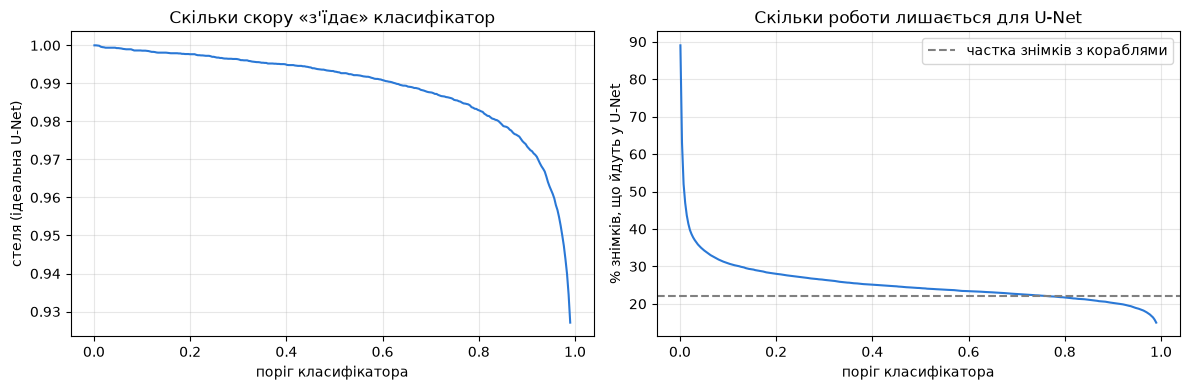

In [6]:
grid = np.linspace(0.001, 0.99, 300)
ceiling = [1 - at_threshold(t)[2] / len(val) for t in grid]
to_unet = [100 * (at_threshold(t)[0] + at_threshold(t)[1]) / len(val) for t in grid]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(grid, ceiling, color=EMPTY_COLOR)
axes[0].set_xlabel("поріг класифікатора")
axes[0].set_ylabel("стеля (ідеальна U-Net)")
axes[0].set_title("Скільки скору «з'їдає» класифікатор")
axes[1].plot(grid, to_unet, color=EMPTY_COLOR)
axes[1].axhline(100 * y_true.mean(), color="gray", linestyle="--", label="частка знімків з кораблями")
axes[1].set_xlabel("поріг класифікатора")
axes[1].set_ylabel("% знімків, що йдуть у U-Net")
axes[1].set_title("Скільки роботи лишається для U-Net")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Аналіз помилок (error analysis)

Дивимось очима на найупевненіші помилки:
- **FN** — знімки з кораблями з найменшим p (модель упевнено каже «порожньо»);
- **FP** — порожні знімки з найбільшим p (модель упевнено «бачить» корабель).

Val-знімків локально немає, тому завантажуємо лише ці 20 файлів через Kaggle API
в `data/val_errors/` (~3 МБ). Уже завантажені файли пропускаються, тож клітинку можна запускати знову.

In [7]:
import sys

import cv2
from kaggle.api.kaggle_api_extended import KaggleApi

sys.path.append(str(ROOT / "src"))
from rle import rle_decode

N_ERRORS = 10
ERRORS_DIR = ROOT / "data" / "val_errors"

false_negatives = val[val["has_ships"]].nsmallest(N_ERRORS, "p").assign(error="FN")
false_positives = val[~val["has_ships"]].nlargest(N_ERRORS, "p").assign(error="FP")
errors = pd.concat([false_negatives, false_positives]).reset_index(drop=True)
errors.to_csv(ROOT / "data" / "error_ids.csv", index=False)
errors[["error", "ImageId", "n_ships", "p"]].round(4)

,error,ImageId,n_ships,p
0,FN,21d722c27.jpg,1,0.0049
1,FN,b927c0494.jpg,1,0.0096
2,FN,2f1063396.jpg,1,0.0112
3,FN,0ebb39de6.jpg,1,0.0112
4,FN,dfbe7e394.jpg,1,0.0120
5,FN,fb16862a2.jpg,1,0.0122
6,FN,bd583e62d.jpg,1,0.0123
7,FN,c9efee725.jpg,1,0.0146
8,FN,b30ecd587.jpg,1,0.0175
9,FN,ba0949ddc.jpg,1,0.0203


In [8]:
api = KaggleApi()
api.authenticate()
ERRORS_DIR.mkdir(parents=True, exist_ok=True)
for image_id in errors["ImageId"]:
    if not (ERRORS_DIR / image_id).exists():
        api.competition_download_file("airbus-ship-detection", f"train_v2/{image_id}", path=ERRORS_DIR, quiet=True)
print("знімків у val_errors:", len(list(ERRORS_DIR.glob("*.jpg"))))

знімків у val_errors: 20


### 5.1. FN — кораблі, які класифікатор «не бачить»

Знімки в повній роздільності 768×768 (модель бачила їх зменшеними до 384). Маска кораблів —
напівпрозора червона. У підписі — p і сумарна площа кораблів у пікселях
(нагадування з EDA: медіанний корабель — 408 пікселів).

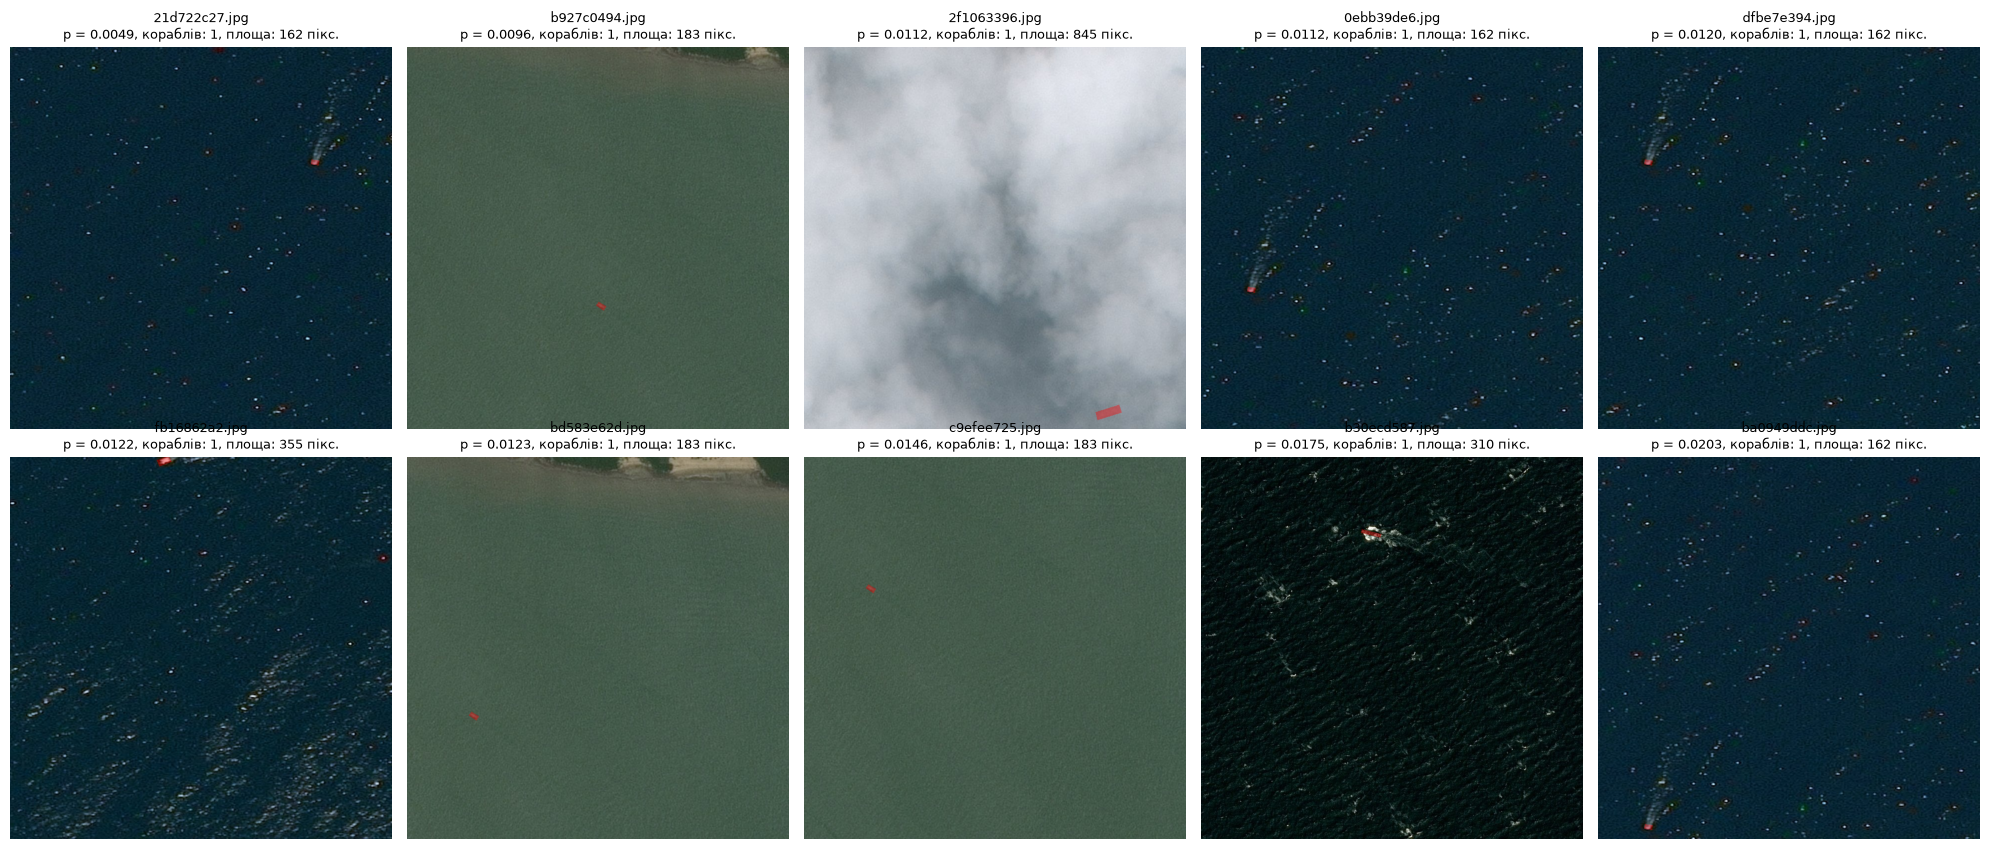

In [9]:
masks = pd.read_csv(ROOT / "data" / "train_ship_segmentations_v2.csv")


def ships_mask(image_id):
    mask = np.zeros((768, 768), dtype=np.uint8)
    for rle in masks.loc[masks["ImageId"] == image_id, "EncodedPixels"].dropna():
        mask |= rle_decode(rle)
    return mask


def show_errors(rows, with_mask):
    fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
    for ax, (_, row) in zip(axes.flat, rows.iterrows()):
        image = cv2.cvtColor(cv2.imread(str(ERRORS_DIR / row["ImageId"])), cv2.COLOR_BGR2RGB)
        title = f"{row['ImageId']}\np = {row['p']:.4f}"
        if with_mask:
            mask = ships_mask(row["ImageId"])
            overlay = image.copy()
            overlay[mask == 1] = [255, 0, 0]
            image = cv2.addWeighted(image, 0.6, overlay, 0.4, 0)
            title += f", кораблів: {row['n_ships']}, площа: {mask.sum()} пікс."
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_errors(errors[errors["error"] == "FN"], with_mask=True)

### 5.2. FP — «кораблі», яких немає

Порожні знімки (масок немає), на яких модель упевнена, що корабель є.

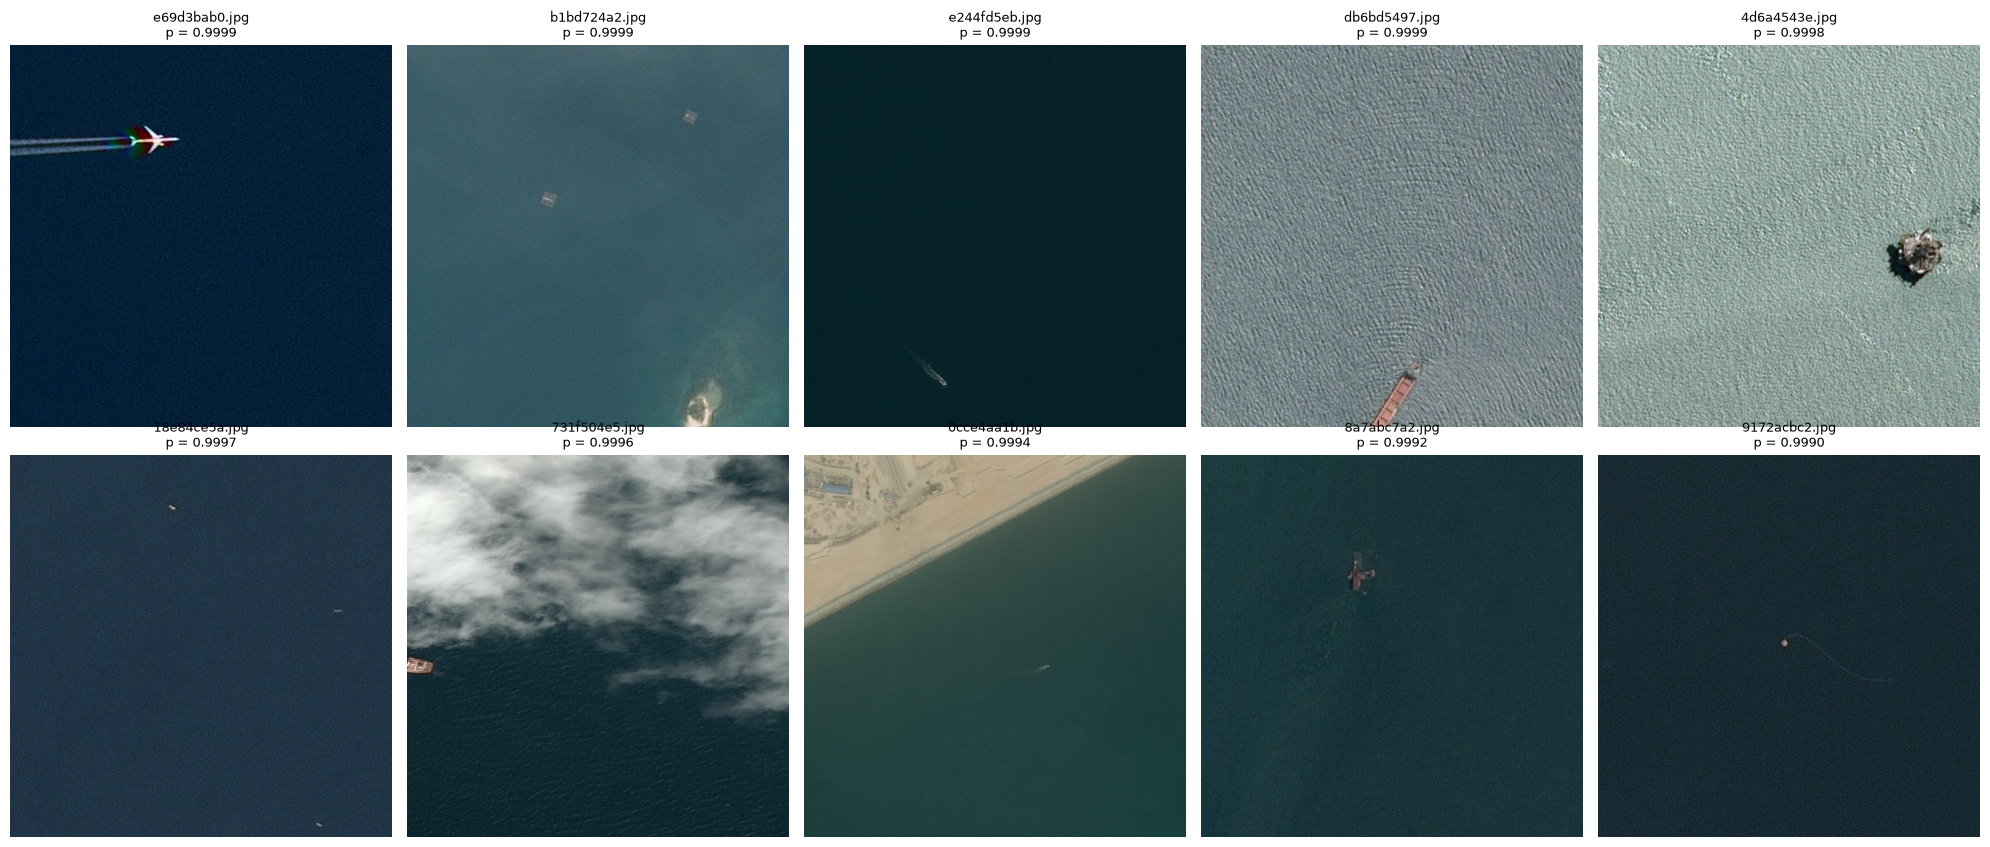

In [10]:
show_errors(errors[errors["error"] == "FP"], with_mask=False)

## Висновки

**Якість:** val ROC-AUC 0.9940, AP 0.9793; перенавчання немає, після 3-ї епохи — плато.

**Пороги:** класифікатор — не вузьке місце. Стеля (з ідеальною U-Net) — 0.9932 на порозі 0.5,
0.9963 на 0.3, 0.9986 на 0.1 (тривіальний сабміт — 0.779). Нижчий поріг піднімає стелю, але шле в U-Net
більше порожніх знімків (31% усіх знімків на порозі 0.1 проти 22% з кораблями), де вона може намалювати
хибну маску. Остаточний поріг — на етапі 8, разом з U-Net; шукати в діапазоні 0.1–0.5.

**FN (кораблі, яких модель «не бачить»):**
- усі 10 — по одному **дрібному** кораблю (162–355 пікс. при медіані 408); при 384 це ~40 пікселів
  серед хвиль → аргумент за більшу роздільність для U-Net;
- **половина — повтори тих самих сцен**: 4 знімки однієї сцени (корабель 162 пікс.) і 3 — іншої
  (183 пікс.). Перекриті шматки великих сцен справді трапляються в різних знімках → ризик data leakage
  між train і val реальний; на етапі 8 обов'язково порівняти val з private LB;
- `2f1063396` — маска під хмарою, корабля не видно (майже помилка розмітки).

**FP (порожні за розміткою, p ≈ 0.999):**
- більшість, схоже, **справжні кораблі без маски** (`db6bd5497`, `e244fd5eb`, `0cce4aa1b`, `18e84ce5a`,
  `731f504e5`, `9172acbc2`) — модель права, розмітка ні (label noise);
- справжні помилки — об'єкти, схожі на корабель: **літак** (`e69d3bab0`), морські платформи
  (`4d6a4543e`, `8a7abc7a2`), квадратні конструкції у воді (`b1bd724a2`).

Модель краща, ніж кажуть метрики, але тестова розмітка, ймовірно, має ті самі пропуски — ці бали
недосяжні для будь-якої моделі.